In [92]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

import shlex
import shutil
import subprocess
import sys
from pathlib import Path

from G4SEE_sims import *

In [93]:
np.sqrt(2e-9)

np.float64(4.4721359549995795e-05)

In [94]:
l_small = 2e-4
n_small = 200000
phi_small = n_small / (l_small**2) # cm^-2

l_big = 2e-4
n_big = 200000
phi_big = n_big / (l_big**2) # cm^-2

In [95]:
if shutil.which("docker") is None:
    print("Docker CLI not found. Install/start Docker Desktop, then run start_g4see_container().")
else:
    start_g4see_container()

Container 'g4see-notebook' is already running.


In [96]:
np.logspace(-2, 0.01, 100)/1000

array([1.00000000e-05, 1.04785944e-05, 1.09800941e-05, 1.15055952e-05,
       1.20562466e-05, 1.26332518e-05, 1.32378721e-05, 1.38714293e-05,
       1.45353081e-05, 1.52309598e-05, 1.59599050e-05, 1.67237372e-05,
       1.75241259e-05, 1.83628207e-05, 1.92416550e-05, 2.01625499e-05,
       2.11275182e-05, 2.21386694e-05, 2.31982137e-05, 2.43084673e-05,
       2.54718569e-05, 2.66909257e-05, 2.79683385e-05, 2.93068875e-05,
       3.07094987e-05, 3.21792381e-05, 3.37193184e-05, 3.53331062e-05,
       3.70241288e-05, 3.87960829e-05, 4.06528417e-05, 4.25984640e-05,
       4.46372026e-05, 4.67735141e-05, 4.90120683e-05, 5.13577585e-05,
       5.38157120e-05, 5.63913019e-05, 5.90901580e-05, 6.19181799e-05,
       6.48815493e-05, 6.79867440e-05, 7.12405515e-05, 7.46500844e-05,
       7.82227956e-05, 8.19664948e-05, 8.58893654e-05, 8.99999823e-05,
       9.43073311e-05, 9.88208272e-05, 1.03550337e-04, 1.08506198e-04,
       1.13699244e-04, 1.19140826e-04, 1.24842839e-04, 1.30817747e-04,
      

In [107]:
E_per_Q_room = 22.5 # the conversion factor from charge to energy in silicon at room temperature -- MeV/pC
Es = [20, 70, 200]
SVs = [200]
BEOLs = [6]
Qcs = np.array([0.1, 0.2, 0.5, 1.0, 1.5, 2.0])/1000
input_folder = "D:/ProtonIrrad/G4SEE_input_files/beam_sizes/"
input_mac_small = "10um.mac"
input_mac_big = "naive_big.mac"
output_folder = "D:/ProtonIrrad/G4SEE_output_files/naive_models/"

In [108]:
ret_small = run_g4see_sv_beol_histogram_sweep(
    energies = Es,
    sv_thicknesses = SVs,
    beol_thicknesses = BEOLs,
    source_mac_path = input_folder + input_mac_small,
    output_folder = output_folder,
    sv_thickness_unit="nm",
    beol_thickness_unit="um",
    generated_mac_folder=None,
    energy_unit="MeV",
)

Container 'g4see-notebook' is already running.
Running G4SEE for 20 MeV...

**************************************************************
 Geant4 version Name: geant4-11-02-patch-02 [MT]   (21-June-2024)
                       Copyright : Geant4 Collaboration
                      References : NIM A 506 (2003), 250-303
                                 : IEEE-TNS 53 (2006), 270-278
                                 : NIM A 835 (2016), 186-225
                             WWW : http://geant4.org/
**************************************************************

Default random seeds: 1098571685, 817390480
which will be overwritten by macro command:  /random/setSeeds  iiii, jjjj

G4SEE path:        /home/g4see
Input macro file:  /home/.g4see_generated_macros/10um_sv_200_nm_beol_6_um_gps_ene_20_MeV.mac
Output directory:  /home/G4SEE_output_files/naive_models/sv_200_nm_beol_6_um_eibtclvx/g4see_energy_sweep_yu07fj12/run_001_20_MeV

PhysicsList::ConstructParticle
Visualization Manager instantiat

In [104]:
E0 = 20
SV0 = 200
BEOL0 = 6
Qc0 = 1/1000

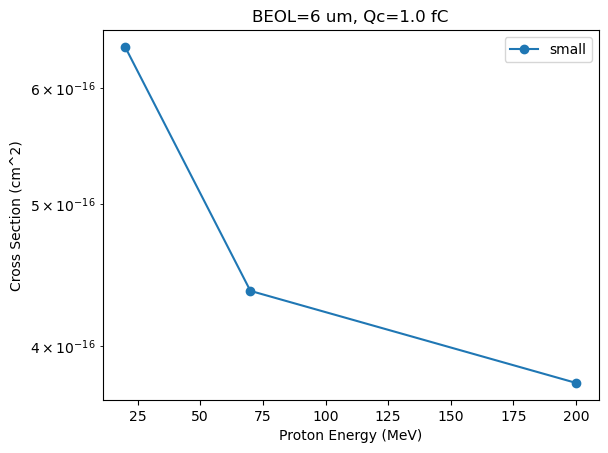

In [102]:

plt.title(f'BEOL={BEOL0} um, Qc={Qc0*1000} fC')
for SV in SVs:
    sigEs_small = []
    for E in Es:
        histE = ret_small[str(SV) + ' nm'][str(BEOL0) + ' um'][str(E) + ' MeV']
        sigE = cross_section(Qc0, histE['Edep'], histE['Counts'], phi=phi_small)
        sigEs_small.append(sigE)
    plt.plot(Es, sigEs_small, marker='o', label=f'small')
plt.xlabel('Proton Energy (MeV)')
plt.ylabel('Cross Section (cm^2)')
plt.yscale('log')
plt.legend()
plt.show()

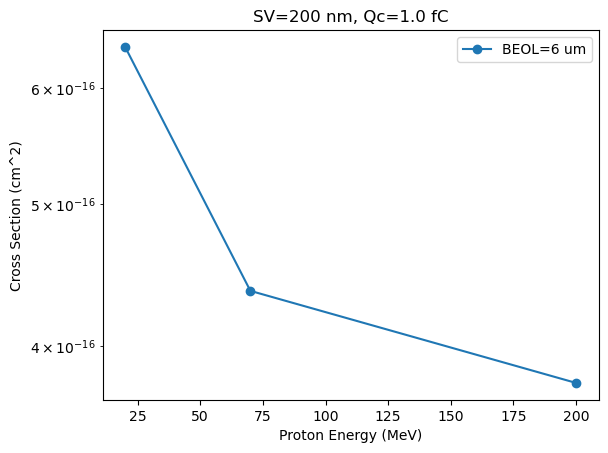

In [105]:

plt.title(f'SV={SV0} nm, Qc={Qc0*1000} fC')
for BEOL in BEOLs:
    sigEs_small = []
    for E in Es: 
        histE = ret_small[str(SV0) + ' nm'][str(BEOL) + ' um'][str(E) + ' MeV']
        sigE = cross_section(Qc0, histE['Edep'], histE['Counts'], phi=phi_small)
        sigEs_small.append(sigE)
    plt.plot(Es, sigEs_small, marker='o', label=f'BEOL={BEOL} um')
plt.xlabel('Proton Energy (MeV)')
plt.ylabel('Cross Section (cm^2)')
plt.yscale('log')
plt.legend()
plt.show()


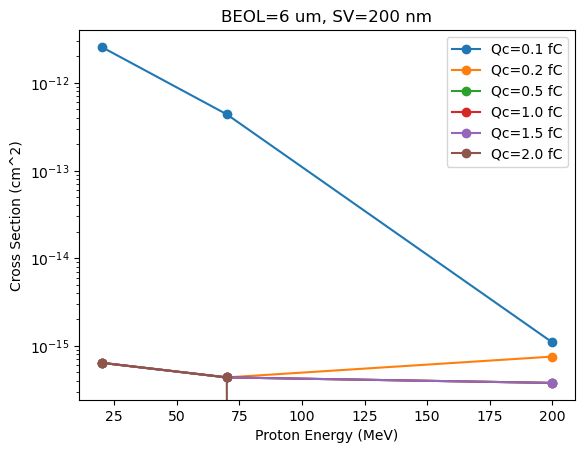

In [106]:
plt.title(f'BEOL={BEOL0} um, SV={SV0} nm')
for Qc in Qcs:
    sigEs = []
    for E in Es:
        histE = ret_small[str(SV0) + ' nm'][str(BEOL0) + ' um'][str(E) + ' MeV']
        sigE = cross_section(Qc, histE['Edep'], histE['Counts'], phi=phi_small)
        sigEs.append(sigE)
    plt.plot(Es, sigEs, marker='o', label=f'Qc={Qc*1000} fC')
plt.xlabel('Proton Energy (MeV)')
plt.ylabel('Cross Section (cm^2)')
plt.yscale('log')
plt.legend()
plt.show()

In [ ]:
stop_g4see_container()

CompletedProcess(args=['docker', 'stop', 'g4see-notebook'], returncode=0)